In [2]:
# ------------------------------
# Importing necessary libraries
# ------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, 
                             log_loss, confusion_matrix, classification_report)
import xgboost as xgb
import lightgbm as lgb
import shap
from tensorflow import keras
from tensorflow.keras import layers
import warnings
warnings.filterwarnings('ignore')

print("Successfully loaded all libraries!")

Successfully loaded all libraries!


In [ ]:
# ---------------------------------------------------
# Data preparation and train/test split - Dataset A
# ---------------------------------------------------

df_dataset = pd.read_csv('../data/processed/nba_dataset_final_a.csv')

def prepare_data(df):
    feature_cols = [col for col in df.columns 
                    if col not in ['GAME_DATE_HOME', 'TEAM_NAME_HOME', 'TEAM_NAME_AWAY', 'WINNER', 'season']]
    
    X = df[feature_cols].astype(float)
    le = LabelEncoder()
    y = le.fit_transform(df['WINNER'].astype(str).values.ravel())
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    return X_train, X_test, y_train, y_test, le, feature_cols

X_train, X_test, y_train, y_test, le, features = prepare_data(df_dataset)

print(f"NBA dataset:")
print(f"  X_train: {X_train.shape}")
print(f"  X_test: {X_test.shape}")
print(f"  Features: {len(features)}")
print(f"  Target classes: {list(le.classes_)}")

NBA dataset:
  X_train: (12086, 45)
  X_test: (3022, 45)
  Features: 45
  Target classes: ['AWAY', 'HOME']


In [ ]:
# ---------------------------------------------------
# Data preparation and train/test split - Dataset B
# ---------------------------------------------------

df_dataset = pd.read_csv('../data/processed/nba_dataset_final_b.csv')

def prepare_data(df):
    feature_cols = [col for col in df.columns 
                    if col not in ['GAME_DATE_HOME', 'TEAM_NAME_HOME', 'TEAM_NAME_AWAY', 'WINNER', 'season']]
    
    X = df[feature_cols].astype(float)
    le = LabelEncoder()
    y = le.fit_transform(df['WINNER'].astype(str).values.ravel())
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    return X_train, X_test, y_train, y_test, le, feature_cols

X_train, X_test, y_train, y_test, le, features = prepare_data(df_dataset)

print(f"NBA dataset:")
print(f"  X_train: {X_train.shape}")
print(f"  X_test: {X_test.shape}")
print(f"  Features: {len(features)}")
print(f"  Target classes: {list(le.classes_)}")

NBA dataset:
  X_train: (6438, 45)
  X_test: (1610, 45)
  Features: 45
  Target classes: ['AWAY', 'HOME']


In [14]:
# -------------------------------
# Training and evaluating models
# -------------------------------

def train_and_evaluate(model, X_train, X_test, y_train, y_test, model_name):
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])
    log_loss_val = log_loss(y_test, y_pred_proba)
    
    results = {
        'Model': model_name,
        'Accuracy': accuracy,
        'F1': f1,
        'ROC-AUC': roc_auc,
        'Log Loss': log_loss_val
    }
    
    return results, model, y_pred, y_pred_proba

all_results = []

print("=" * 70)
print("NBA Dataset (4 models)")
print("=" * 70)

# Logistic regression
print("\n1. Logistic regression...")
lr = LogisticRegression(max_iter=1000, random_state=42)
results_lr, model_lr, _, _ = train_and_evaluate(
    lr, X_train, X_test, y_train, y_test, "Logistic Regression"
)
all_results.append(results_lr)
print(f"  Accuracy: {results_lr['Accuracy']:.4f}")

# Random Forest
print("\n2. Random Forest...")
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
results_rf, model_rf, _, _ = train_and_evaluate(
    rf, X_train, X_test, y_train, y_test, "Random Forest"
)
all_results.append(results_rf)
print(f"  Accuracy: {results_rf['Accuracy']:.4f}")

# XGBoost
print("\n3. XGBoost...")
xgb_model = xgb.XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbosity=0)
results_xgb, model_xgb, _, _ = train_and_evaluate(
    xgb_model, X_train, X_test, y_train, y_test, "XGBoost"
)
all_results.append(results_xgb)
print(f"  Accuracy: {results_xgb['Accuracy']:.4f}")

# Summary
results_df = pd.DataFrame(all_results)
print("\n" + "=" * 70)
print("SUMMARY OF NBA MODELS")
print("=" * 70)
print(results_df.to_string(index=False))


NBA Dataset (4 models)

1. Logistic regression...
  Accuracy: 0.6691

2. Random Forest...
  Accuracy: 0.6380

3. XGBoost...
  Accuracy: 0.6155

SUMMARY OF NBA MODELS
              Model  Accuracy       F1  ROC-AUC  Log Loss
Logistic Regression  0.669093 0.663158 0.708989  0.611887
      Random Forest  0.637988 0.633841 0.689018  0.625131
            XGBoost  0.615486 0.613245 0.646680  0.694682


In [15]:
# ------------------------------------------------------------------------
# Optimization Phase 1: Logistic Regression with Normalization and Tuning
# ------------------------------------------------------------------------

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

optimized_results = []

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'saga'],
    'max_iter': [1000, 2000]
}

lr_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train_scaled, y_train)

print("="*50)
print("NBA Dataset - Logistic Regression Optimization")
print("="*50)
print(f"\nBest parameters: {lr_grid.best_params_}")
print(f"Best CV accuracy: {lr_grid.best_score_:.4f}")

best_lr = lr_grid.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)
y_pred_proba_lr = best_lr.predict_proba(X_test_scaled)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average='weighted')
roc_auc_lr = roc_auc_score(y_test, y_pred_proba_lr[:,1])
log_loss_lr = log_loss(y_test, y_pred_proba_lr)

optimized_results.append([accuracy_lr, f1_lr, roc_auc_lr, log_loss_lr])

print(f"\nTest Accuracy: {accuracy_lr:.4f}")
print(f"Test F1: {f1_lr:.4f}")
print(f"Test ROC-AUC: {roc_auc_lr:.4f}")
print(f"Test Log Loss: {log_loss_lr:.4f}")


Fitting 5 folds for each of 24 candidates, totalling 120 fits
NBA Dataset - Logistic Regression Optimization

Best parameters: {'C': 100, 'max_iter': 1000, 'solver': 'lbfgs'}
Best CV accuracy: 0.6474

Test Accuracy: 0.6625
Test F1: 0.6560
Test ROC-AUC: 0.7089
Test Log Loss: 0.6123


In [16]:
# -------------------------------------------
# Optimization Phase 2: Random Forest Tuning
# -------------------------------------------

from sklearn.model_selection import RandomizedSearchCV

param_grid_rf = {
    'n_estimators': [100, 150, 200, 250, 300],
    'max_depth': [None, 10, 20, 30, 40],
    'min_samples_split': [2, 5, 7, 10],
    'min_samples_leaf': [2, 3, 4, 5]
}

total_combinations = 5 * 5 * 4 * 4
print(f"Total combinations: {total_combinations}")
print(f"Using RandomizedSearchCV with 100 random combinations instead of all {total_combinations}")

rf_random = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid_rf,
    n_iter=100,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

rf_random.fit(X_train, y_train)

print("="*50)
print("NBA Dataset - Random Forest Optimization")
print("="*50)
print(f"\nBest parameters: {rf_random.best_params_}")
print(f"Best CV accuracy: {rf_random.best_score_:.4f}")

best_rf = rf_random.best_estimator_
y_pred_rf = best_rf.predict(X_test)
y_pred_proba_rf = best_rf.predict_proba(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf[:,1])
log_loss_rf = log_loss(y_test, y_pred_proba_rf)

print(f"\nTest Accuracy: {accuracy_rf:.4f}")
print(f"Test F1: {f1_rf:.4f}")
print(f"Test ROC-AUC: {roc_auc_rf:.4f}")
print(f"Test Log Loss: {log_loss_rf:.4f}")

Total combinations: 400
Using RandomizedSearchCV with 100 random combinations instead of all 400
Fitting 5 folds for each of 100 candidates, totalling 500 fits
NBA Dataset - Random Forest Optimization

Best parameters: {'n_estimators': 200, 'min_samples_split': 7, 'min_samples_leaf': 4, 'max_depth': 10}
Best CV accuracy: 0.6427

Test Accuracy: 0.6529
Test F1: 0.6452
Test ROC-AUC: 0.7068
Test Log Loss: 0.6156


In [17]:
# -------------------------------------
# Optimization Phase 3: XGBoost Tuning
# -------------------------------------

param_grid_xgb = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

total_combinations = 4 * 4 * 4 * 3 * 3
print(f"Total combinations: {total_combinations}")
print(f"Using RandomizedSearchCV with 100 random combinations")

xgb_random = RandomizedSearchCV(
    xgb.XGBClassifier(random_state=42, n_jobs=-1, verbosity=0, use_label_encoder=False),
    param_grid_xgb,
    n_iter=100,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

xgb_random.fit(X_train, y_train)

print("="*50)
print("NBA Dataset - XGBoost Optimization")
print("="*50)
print(f"\nBest parameters: {xgb_random.best_params_}")
print(f"Best CV accuracy: {xgb_random.best_score_:.4f}")

best_xgb = xgb_random.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)
y_pred_proba_xgb = best_xgb.predict_proba(X_test)

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb, average='weighted')
roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb[:,1])
log_loss_xgb = log_loss(y_test, y_pred_proba_xgb)

print(f"\nTest Accuracy: {accuracy_xgb:.4f}")
print(f"Test F1: {f1_xgb:.4f}")
print(f"Test ROC-AUC: {roc_auc_xgb:.4f}")
print(f"Test Log Loss: {log_loss_xgb:.4f}")

Total combinations: 576
Using RandomizedSearchCV with 100 random combinations
Fitting 5 folds for each of 100 candidates, totalling 500 fits
NBA Dataset - XGBoost Optimization

Best parameters: {'subsample': 0.6, 'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
Best CV accuracy: 0.6438

Test Accuracy: 0.6559
Test F1: 0.6485
Test ROC-AUC: 0.7004
Test Log Loss: 0.6188


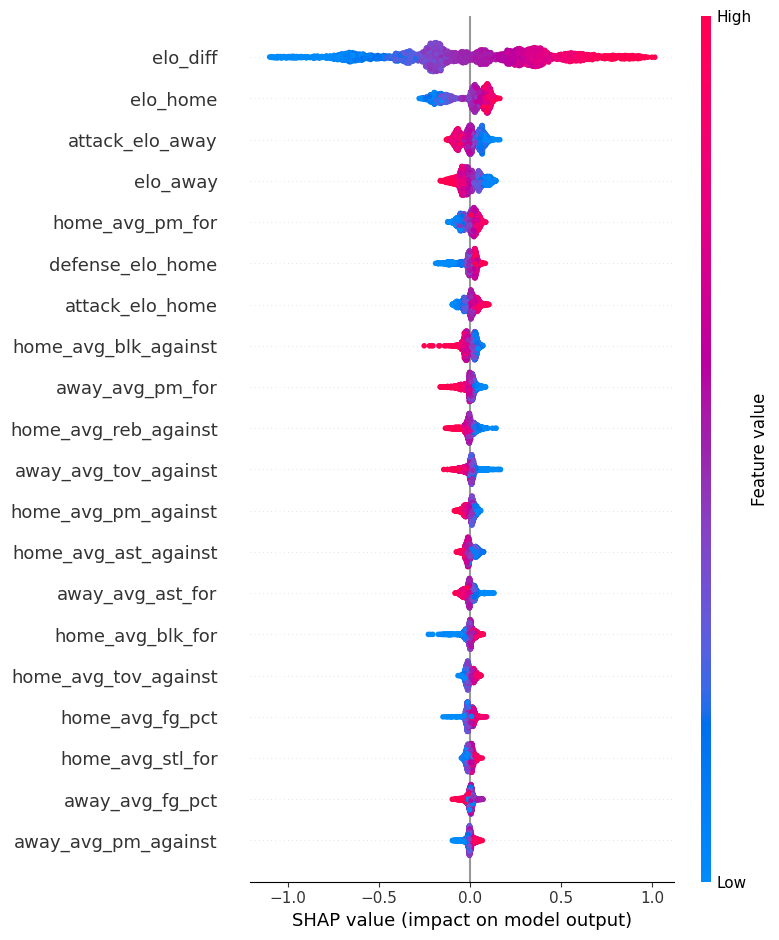

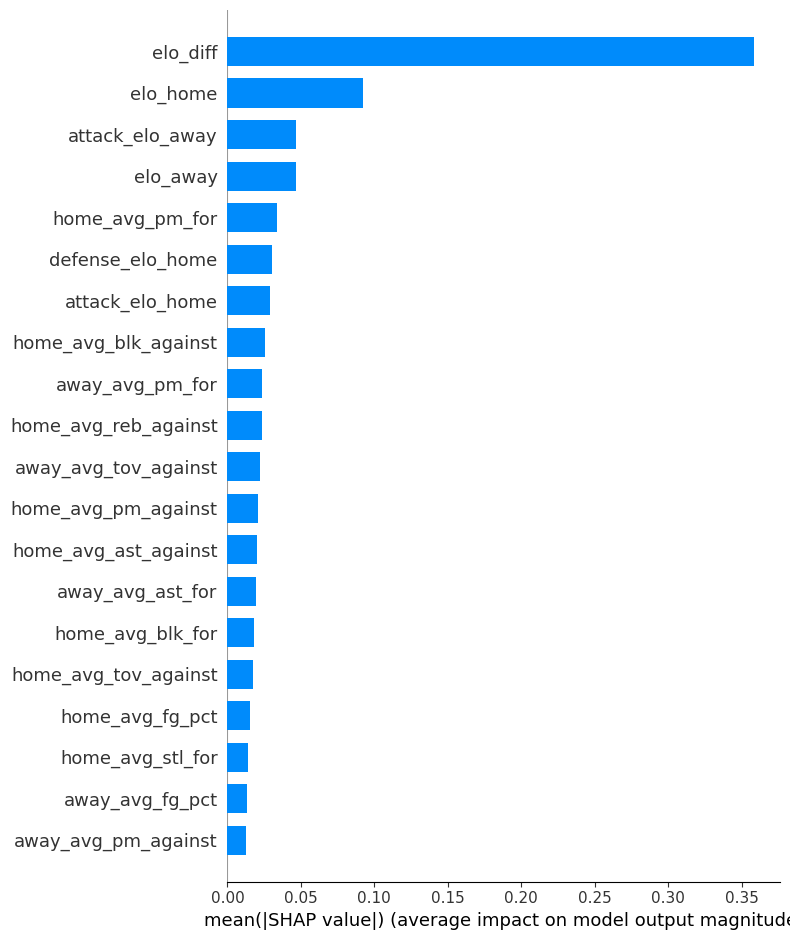

100%|===================| 6032/6044 [02:41<00:00]        

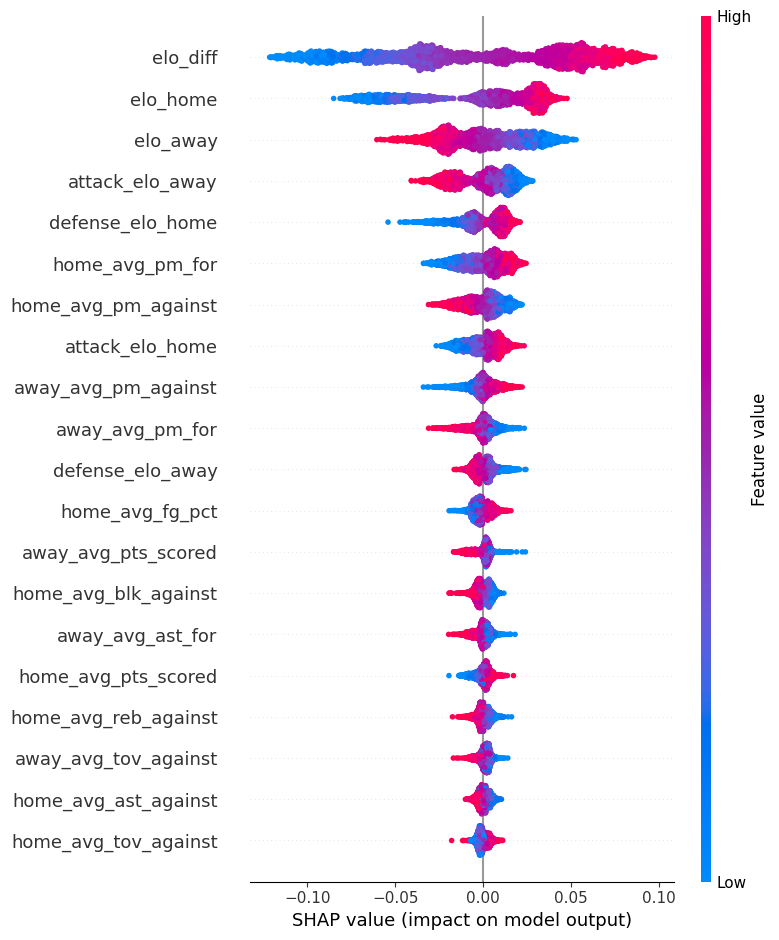

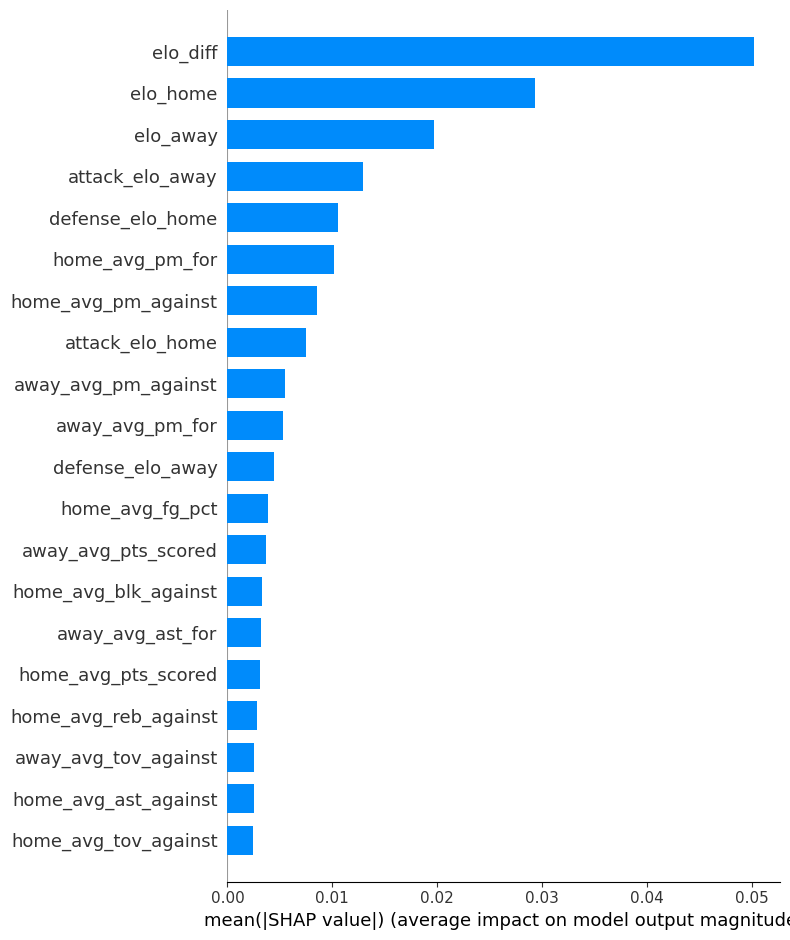

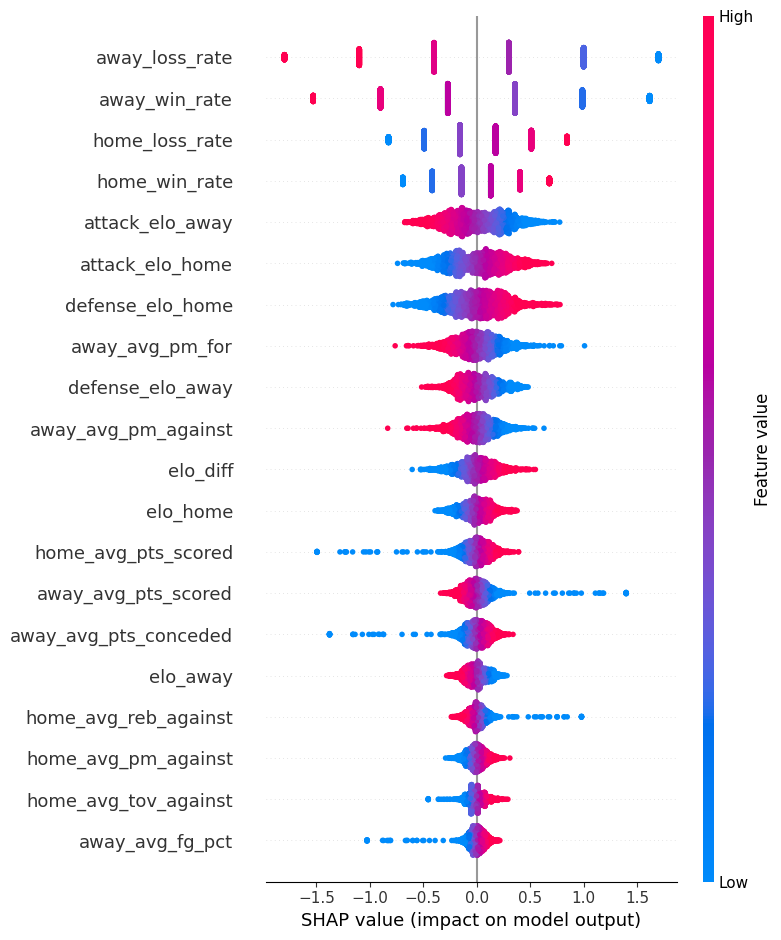

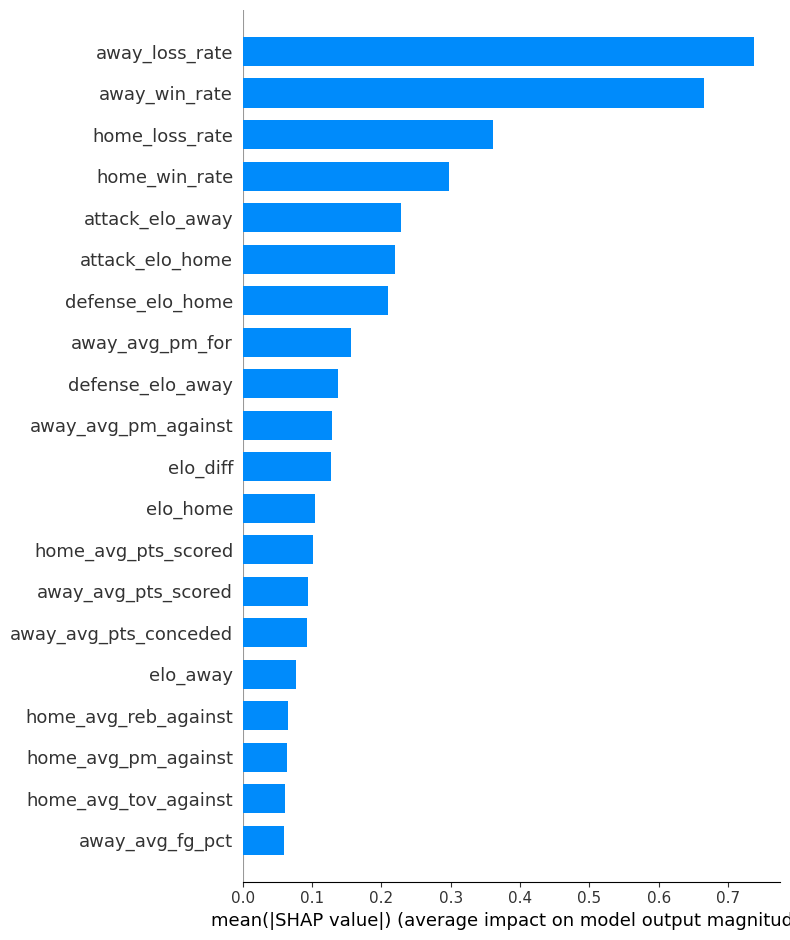

In [18]:
# --------------
# SHAP Analysis
# --------------

# XGBoost SHAP analysis
explainer_xgb = shap.TreeExplainer(best_xgb)
shap_values_xgb = explainer_xgb.shap_values(X_test)
shap.summary_plot(shap_values_xgb, X_test, feature_names=X_train.columns)
plt.savefig("../results/figures/31_shap_xgb.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_xgb, X_test, feature_names=X_train.columns, plot_type="bar")
plt.savefig("../results/figures/32_shap_bar_xgb.png", dpi=300, bbox_inches='tight')
plt.close()

# Random Forest SHAP analysis
explainer_rf = shap.Explainer(best_rf, X_train)
shap_values_rf = explainer_rf(X_test)
shap.summary_plot(shap_values_rf[:, :, 1], X_test, feature_names=X_train.columns)
plt.savefig("../results/figures/33_shap_rf.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_rf[:, :, 1], X_test, feature_names=X_train.columns, plot_type="bar")
plt.savefig("../results/figures/34_shap_bar_rf.png", dpi=300, bbox_inches='tight')
plt.close()

# Logistic Regression SHAP analysis
explainer_lr = shap.LinearExplainer(best_lr, X_train_scaled)
shap_values_lr = explainer_lr(X_test_scaled)
shap.summary_plot(shap_values_lr.values, X_test_scaled, feature_names=X_train.columns)
plt.savefig("../results/figures/35_shap_lr.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_lr.values, X_test_scaled, feature_names=X_train.columns, plot_type="bar")
plt.savefig("../results/figures/36_shap_bar_lr.png", dpi=300, bbox_inches='tight')
plt.close()